# Tutorial 2: a continuous target on Visium HD, explained at its own scale

Glomeruli in human kidney cortex. The target is a podocyte programme score (mean log CP10K of ten podocyte genes per 16 µm bin); the question is which other genes rebuild it, and at which scale.

Data: a Visium HD kidney section at 8 µm bins as an `.h5ad` with the bin indices in `obs` (`grid_row`, `grid_col`; Space Ranger names them `array_row`, `array_col`). Any HD section with cortex works; the numbers below are for section iu04, tissue fragment 3.

Five things the tutorial shows:

1. the target split into LOW (> 200 µm), MID (40–200 µm) and HIGH (< 40 µm): the glomeruli live in the MID band;
2. the band-matched fit reproduces the MID band on unseen tissue far better than chance, and better than fitting the genes unsplit;
3. the genes that carry the MID band sit on the glomeruli; the genes that define the target were withheld, so they are found, not planted;
4. the same glomeruli drawn as a region are a MID-dominated graph signal (band shares LOW 0.09, MID 0.33, HIGH 0.27) whose MID band is reproduced at 0.92 on unseen tissue;
5. which genes can be trusted: every gene on its own on unseen tissue, against the best single gene of random placements, with necessity and reproducibility alongside.

In [1]:
import numpy as np, pandas as pd, anndata as ad
import scalematch as sm
from scalematch.plotting import plot_target_bands, plot_curves, plot_contributions

a = ad.read_h5ad("data/kidney/iu04_tissue_3_8um.h5ad")
counts, r, c, members = sm.aggregate_bins(a.X, a.obs["grid_row"], a.obs["grid_col"], factor=2)   # 8 um -> 16 um
coords = np.column_stack([c * 16.0, r * 16.0])                                                     # micrometres
genes = np.asarray(a.var_names).astype(str)
print(counts.shape, "bins x genes at 16 um")

(12725, 18085) bins x genes at 16 um


## 1. Target and dictionary

The podocyte programme is the mean log CP10K of a published signature. Every gene used in the signature is passed as `exclude_genes`, so the explanation cannot be circular. The dictionary is the 500 most variable remaining genes.

In [2]:
PODOCYTE = ["NPHS1", "NPHS2", "PODXL", "PTPRO", "WT1", "SYNPO", "CLIC5", "NDNF", "DDN", "PTPRQ"]
target, used = sm.programme_score(counts, genes, PODOCYTE)
print(len(used), "signature genes present; score > 0 in", round(float((target > 0).mean()), 3), "of bins")

10 signature genes present; score > 0 in 0.125 of bins


## 2. Run

Pitch 16 µm; bands at 40 and 200 µm. `surrogate` nulls are random fields with the same energy in every band as the target (same spectrum, no anatomy); `rigid` nulls slide the whole field along the section. Twenty of each here; forty is the default.

In [3]:
res = sm.explain(counts, genes, coords, target, pitch_um=16, exclude_genes=used, sigmas=(40, 200),
                 designs=("perband", "raw"), null_kinds=("surrogate", "rigid"), n_null=20, seed=0)
print(res.summary())

[scalematch     0s] graph: 12659 units kept of 12725, pitch 16.00 units = 16 um


[scalematch     0s] dictionary: 500 genes, 10 excluded by name


[scalematch   240s] bands done; target shares LOW 0.08, MID 0.16, HIGH 0.56


[scalematch   244s] perband: A 0.387 best 0.410 | explained LOW 0.92, MID 0.79, HIGH 0.11


[scalematch   247s] raw: A 0.235 best 0.279 | explained LOW 0.59, MID 0.61, HIGH 0.02


[scalematch   403s] null surrogate: 20 draws scored


[scalematch   645s] null rigid: 20 draws scored


[scalematch   646s] attribution done: NES, NPNT, RIPOR1, COL18A1, CCN2, BCAM, ENPEP, SLC9A3R2


field target on 12659 units, pitch 16 um, bands 40/200 um
held-out: A = 0.387, best 1-NMSE = 0.410 at k = 29
explained per band (held-out): LOW 0.92, MID 0.79, HIGH 0.11
target band shares: LOW 0.08, MID 0.16, HIGH 0.56
perband/surrogate/A: p = 0.048, excess over null mean = +0.385 (n = 20)
perband/surrogate/best: p = 0.048, excess over null mean = +0.406 (n = 20)
perband/surrogate/explained_MID: p = 0.048, excess over null mean = +1.021 (n = 20)
perband/rigid/A: p = 0.048, excess over null mean = +0.378 (n = 20)
perband/rigid/best: p = 0.048, excess over null mean = +0.402 (n = 20)
perband/rigid/explained_MID: p = 0.048, excess over null mean = +1.005 (n = 20)
top genes (order, dominant band): NES (MID), NPNT (HIGH), RIPOR1 (MID), COL18A1 (LOW), CCN2 (HIGH), BCAM (LOW), ENPEP (MID), SLC9A3R2 (LOW), NOTCH3 (LOW), BST2 (HIGH)


Reading it, three questions:

* **Real?** `p` and `excess`. A random field with the same spectrum (`surrogate`) has its MID band explained at −0.23 on average; the podocyte score reaches 0.79 (`excess` +1.02). The field moved rigidly along the section (`rigid`) does no better. p = 0.048 is the floor for 20 draws: none of the 20 copies came close.
* **How big?** `explained per band`: LOW 0.92, MID 0.79, HIGH 0.11. The coarse part (a cortex-wide trend) and the 40–200 µm part (the glomeruli) are reproduced on unseen strips; the bin-level part is not. So the structure is a 40–200 µm thing, and what sits below 40 µm is grain.
* **Which genes?** `gene_table` sorted by `rms_MID`, below.

Supporting detail: `target band shares` say where the target's own variance sits: 56% in HIGH, 16% in MID. A band with a large share and a low explained value is noise, which is what the HIGH band of a sparse-count score is. `raw` fits the genes unsplit and explains less of every band.

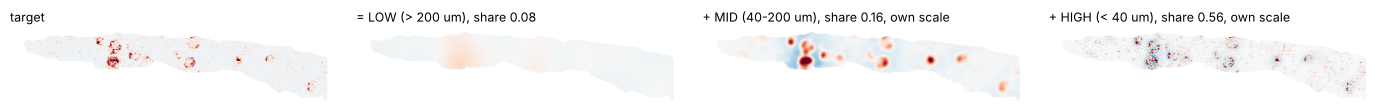

In [4]:
fig = plot_target_bands(res, s=2.5)

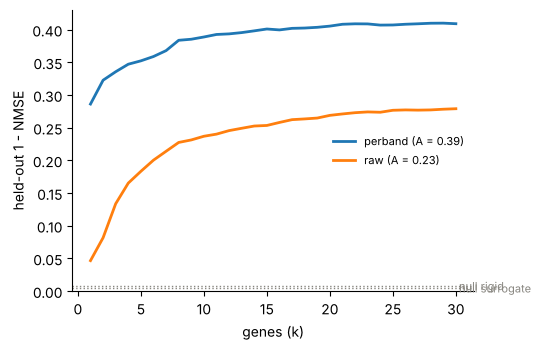

In [5]:
fig = plot_curves(res)

## 3. Which genes, at which scale

`gene_table` lists the 30 selected genes with the RMS of their contribution per band. The MID carriers (NES, NPNT, RIPOR1) are podocyte and glomerular basement membrane genes; the LOW carriers (C7, PLPP1, SLC9A3R2) follow cortex-wide trends. No single gene carries a band on its own.

In [6]:
t = res.gene_table
print("MID carriers:", t.sort_values("rms_MID", ascending=False).gene.head(6).tolist())
print("LOW carriers:", t.sort_values("rms_LOW", ascending=False).gene.head(6).tolist())
t.head(10)[["order", "gene", "rms_LOW", "rms_MID", "rms_HIGH", "dominant"]].round(3)

MID carriers: ['NES', 'NPNT', 'RIPOR1', 'MSN', 'NOTCH3', 'ENPEP']
LOW carriers: ['C7', 'PLPP1', 'NES', 'SLC9A3R2', 'BCAM', 'RIPOR1']


,order,gene,rms_LOW,rms_MID,rms_HIGH,dominant
0,1,NES,0.025,0.037,0.023,MID
1,2,NPNT,0.014,0.024,0.028,HIGH
2,3,RIPOR1,0.020,0.022,0.017,MID
3,4,COL18A1,0.012,0.009,0.002,LOW
4,5,CCN2,0.008,0.011,0.018,HIGH
5,6,BCAM,0.023,0.009,0.019,LOW
6,7,ENPEP,0.009,0.014,0.011,MID
7,8,SLC9A3R2,0.024,0.010,0.011,LOW
8,9,NOTCH3,0.019,0.015,0.011,LOW
9,10,BST2,0.001,0.009,0.010,HIGH


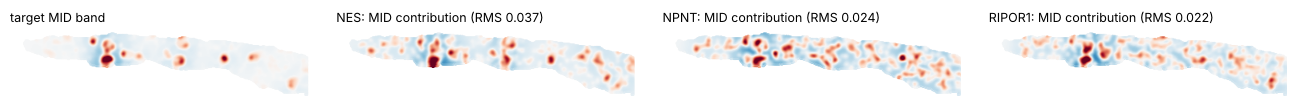

In [7]:
fig = plot_contributions(res, band="MID", n=3, s=2.5)

The selected genes are representatives. `modules` tells, for every gene in the dictionary, whether it is selected, covered by a representative (correlated with the target but reproducible from the selected set), relevant but uncovered, or unrelated. Endothelial genes such as EMCN and CD34 are typically covered by NES or NPNT: they mark the glomeruli too, and the sparse list would hide them without this table.

In [8]:
m = res.modules[res.modules.band == "MID"]
print(m.status.value_counts().to_dict())
m[m.status == "covered"].head(8).round(3)

{'unrelated': 385, 'covered': 71, 'selected': 30, 'relevant-uncovered': 14}


,gene,band,relevance,coverage,representative,status
500,EMCN,MID,0.683,0.875,TGFBR2,covered
501,SYNE1,MID,0.681,0.863,PLPP1,covered
502,PLPP3,MID,0.632,0.686,IGFBP5,covered
503,LGALS1,MID,0.627,0.825,AEBP1,covered
504,CD34,MID,0.612,0.790,IGFBP5,covered
505,TNS2,MID,0.605,0.723,SLC9A3R2,covered
506,TSC22D1,MID,0.584,0.764,NOTCH3,covered
507,ETS1,MID,0.580,0.709,PLPP1,covered


## 4. The same glomeruli as a region: a MID-dominated target

A programme score is a noisy field; more than half of its variance is bin-level grain. A drawn region has no grain, so it shows the scale reading more plainly. The Space Ranger clustering stored in `obs` puts the glomeruli in cluster 4 (the podocyte score averages 0.43 there and under 0.06 in every other cluster of more than 100 bins). The majority cluster per 16 µm bin, with pieces under 20 bins dropped, gives twelve glomeruli of 110–230 µm equivalent diameter. The podocyte genes are withheld as before.

In [9]:
cluster16 = sm.aggregate_labels(a.obs["cluster"].astype(int), a.obs["grid_row"], a.obs["grid_col"], factor=2)
print(pd.Series(target).groupby(cluster16).agg(["mean", "size"]).query("size > 100").sort_values("mean", ascending=False).head(3).round(3))

glom, comp = sm.clean_region(cluster16 == 4, coords, min_units=20)
sizes = np.bincount(comp[comp >= 0])
print(glom.sum(), "bins in", len(sizes), "glomeruli; equivalent diameters (um):", np.round(2 * np.sqrt(sizes * 16 ** 2 / np.pi)).astype(int).tolist())

res_r = sm.explain(counts, genes, coords, glom, pitch_um=16, exclude_genes=used, sigmas=(40, 200),
                   designs=("perband", "raw"), null_kinds=("rigid", "blob"), n_null=20, seed=0)
print(res_r.summary())

    mean  size
4  0.434  1261
8  0.054   546
1  0.048  4076
1123 bins in 12 glomeruli; equivalent diameters (um): [146, 228, 135, 227, 210, 125, 136, 202, 153, 199, 107, 173]
[scalematch     0s] graph: 12659 units kept of 12725, pitch 16.00 units = 16 um


[scalematch     0s] dictionary: 500 genes, 10 excluded by name


[scalematch   225s] bands done; target shares LOW 0.09, MID 0.33, HIGH 0.27


[scalematch   225s] strips: [2532, 2532, 2531, 2532, 2532] units, region units per strip [130, 481, 328, 92, 92]


[scalematch   229s] perband: A 0.701 best 0.723 | explained LOW 0.97, MID 0.92, HIGH 0.22


[scalematch   231s] raw: A 0.511 best 0.585 | explained LOW 0.88, MID 0.85, HIGH -0.14


[scalematch   386s] null rigid: 20 draws scored


[scalematch   545s] null blob: 20 draws scored


[scalematch   547s] attribution done: EMCN, IGFBP5, COL1A1, SYNE1, SLC9A3R2, CCN2, TSC22D1, RGS5


region target on 12659 units, pitch 16 um, bands 40/200 um
held-out: A = 0.701, best 1-NMSE = 0.723 at k = 30
explained per band (held-out): LOW 0.97, MID 0.92, HIGH 0.22
target band shares: LOW 0.09, MID 0.33, HIGH 0.27
perband/rigid/A: p = 0.048, excess over null mean = +0.698 (n = 20)
perband/rigid/best: p = 0.048, excess over null mean = +0.713 (n = 20)
perband/rigid/explained_MID: p = 0.048, excess over null mean = +1.151 (n = 20)
perband/blob/A: p = 0.048, excess over null mean = +0.556 (n = 20)
perband/blob/best: p = 0.048, excess over null mean = +0.528 (n = 20)
perband/blob/explained_MID: p = 0.048, excess over null mean = +1.341 (n = 20)
top genes (order, dominant band): EMCN (LOW), IGFBP5 (LOW), COL1A1 (LOW), SYNE1 (MID), SLC9A3R2 (LOW), CCN2 (MID), TSC22D1 (LOW), RGS5 (MID), C7 (MID), PLPP1 (MID)


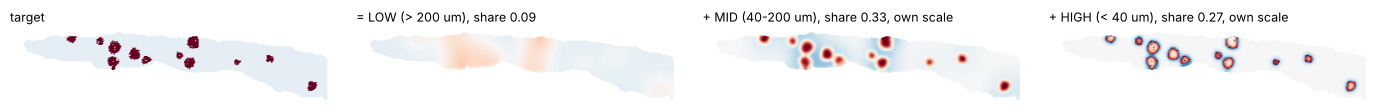

In [10]:
fig = plot_target_bands(res_r, s=2.5)

The region as a graph signal: LOW is a faint cortex-wide tint (share 0.09), MID is the glomeruli themselves (share 0.33), HIGH is their rims (share 0.27). The same three questions:

* **Real?** The twelve outlines placed elsewhere on the section (`rigid`) score 0.01; random connected regions of the same size (`blob`) score 0.19, because one large blob is a coarse object that cortex-wide gradients fit a little. The glomeruli score 0.72. In the MID band the copies are explained at −0.24 and −0.42, the glomeruli at 0.92.
* **How big?** LOW 0.97, MID 0.92, HIGH 0.22. A 40–200 µm structure, reproduced almost entirely; the rims are only partly predictable.
* **Which genes?** The MID carriers are EMCN and IGFBP5 with a positive sign and RGS5, COL1A1 and C7 with a negative sign: endothelium marks the glomerular tuft, and vascular smooth muscle and interstitial collagen mark what is not a glomerulus. None of the withheld podocyte genes is needed; with nothing withheld the result is the same (A 0.70, MID 0.92) and PODXL enters eighth.

Against the field version above, the region moves the MID-band explained variance from 0.79 to 0.92 and the LOW/MID/HIGH shares from 0.08/0.16/0.56 to 0.09/0.33/0.27: the structure was the same, the grain is gone.

MID carriers: [['EMCN', 0.036], ['RGS5', -0.026], ['IGFBP5', 0.018], ['SYNE1', 0.017], ['COL1A1', -0.016], ['C7', -0.016]]
{'unrelated': 343, 'covered': 84, 'relevant-uncovered': 43, 'selected': 30}


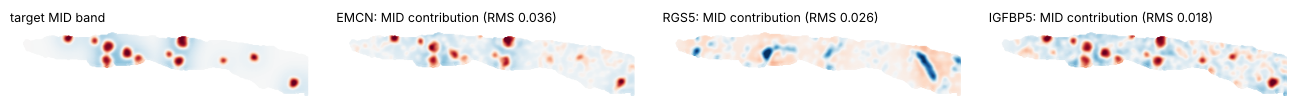

In [11]:
t = res_r.gene_table
print("MID carriers:", t.sort_values("rms_MID", ascending=False)[["gene", "coef_MID"]].head(6).round(3).values.tolist())
m = res_r.modules[res_r.modules.band == "MID"]
print(m.status.value_counts().to_dict())
fig = plot_contributions(res_r, band="MID", n=3, s=2.5)

## 5. Which genes can be trusted

The list above is one fit. `confidence` asks, for every gene in the dictionary, how much of the target it reproduces **on its own** on the held-out strips (`alone`, a 1 − NMSE), and compares that with the best single gene of twenty random placements of the same region. A gene whose `alone` beats every placement's best gene (p = 0.048, the floor for twenty) is supported: it follows the glomeruli better than any gene follows a random set of twelve outlines. Two more columns qualify it: `drop`, what the full fit loses on held-out strips when the gene is removed and the rest refitted (small when other genes stand in for it), and `freq`, how often the gene is among the first fifteen chosen when the section is half-sampled by 400 µm tiles. Genes that stand in for one another are grouped in `conf.modules`.

In [12]:
conf_r = sm.confidence(res_r, seed=0)
print(conf_r.summary())

[confidence] 12 modules among the 30 selected genes; best single gene alone 0.628 (EMCN)


[confidence] 20 random placements: best single gene 0.062 on average, 0.137 at most; 65 genes above that bar


[confidence] 100 half-samplings of 35 tiles (400 um): 6 genes with freq >= 0.8; random placements reach 0.64 at most


[confidence] supported: 65 genes; together they reach 0.687 held-out


confidence: 20 random placements; 100 half-samplings of 35 tiles (400 um), 15 genes per run
supported genes, 65 with p <= 0.05 (held-out 1-NMSE alone, freq, sign and band): EMCN (0.63, 1.00, +LOW), PLPP1 (0.59, 0.83, +MID), SYNE1 (0.59, 1.00, +MID), SLC9A3R2 (0.58, 0.96, +LOW), IGFBP5 (0.57, 1.00, +LOW), TSC22D1 (0.53, 0.65, +LOW), CD34 (0.52, 0.31, +LOW), ETS1 (0.49, 0.00, +LOW), TGFBR2 (0.48, 0.74, +LOW), TNS2 (0.44, 0.13, +LOW), PECAM1 (0.43, 0.38, +HIGH), PLPP3 (0.42, 0.08, +LOW), LGALS1 (0.42, 0.71, +MID), RRAS (0.41, 0.10, +LOW), ETS2 (0.40, 0.01, +LOW), PDGFRB (0.40, 0.42, +LOW), EGFL7 (0.39, 0.04, +LOW), EPAS1 (0.38, 0.58, +MID), SPTBN1 (0.37, 0.19, +MID), NES (0.36, 0.21, +HIGH) and 45 more
random placements: best single gene 0.062 on average, 0.137 at most; best module 0.060 / 0.134; most stable gene 0.50 / 0.64
supported modules, 10 (members, held-out 1-NMSE together, p): [EMCN+, PLPP1+, SYNE1+, SLC9A3R2+, TGFBR2+] 0.66, 0.048; [TSC22D1+, TNS2+, LGALS1+, PDGFRB+, BST2+, A2M+

In [13]:
conf_r.table.head(12)[["gene", "module", "sign", "alone", "alone_MID", "p", "drop", "freq", "sign_consistency"]].round(3)

,gene,module,sign,alone,alone_MID,p,drop,freq,sign_consistency
0,EMCN,0,+,0.628,0.845,0.048,0.006,1.00,1.000
1,PLPP1,0,+,0.593,0.807,0.048,0.000,0.83,0.988
2,SYNE1,0,+,0.591,0.790,0.048,0.004,1.00,1.000
3,SLC9A3R2,0,+,0.579,0.747,0.048,0.000,0.96,0.771
4,IGFBP5,1,+,0.567,0.780,0.048,0.007,1.00,0.750
5,TSC22D1,4,+,0.526,0.667,0.048,0.002,0.65,0.985
6,CD34,6,+,0.519,0.649,0.048,-0.000,0.31,0.742
7,ETS1,-1,+,0.494,0.619,0.048,NaN,0.00,NaN
8,TGFBR2,0,+,0.480,0.659,0.048,0.003,0.74,0.851
9,TNS2,4,+,0.435,0.547,0.048,0.000,0.13,0.615


In [14]:
conf_r.modules.head(8)[["module", "n", "genes", "alone", "p", "drop", "freq_module"]].round(3)

,module,n,genes,alone,p,drop,freq_module
0,0,5,"EMCN+, PLPP1+, SYNE1+, SLC9A3R2+, TGFBR2+",0.660,0.048,0.027,1.00
1,4,9,"TSC22D1+, TNS2+, LGALS1+, PDGFRB+, BST2+, A2M+...",0.600,0.048,0.030,1.00
2,1,2,"IGFBP5+, PLPP3+",0.574,0.048,0.006,1.00
3,6,2,"CD34+, PECAM1+",0.534,0.048,-0.000,0.63
4,5,2,"EPAS1+, RGS5-",0.481,0.048,0.008,0.86
5,9,2,"LMNA+, CLU-",0.382,0.048,0.001,0.20
6,7,2,"SPTBN1+, AQP1+",0.376,0.048,0.002,0.45
7,10,1,NES+,0.358,0.048,-0.002,0.21


Reading it. EMCN alone reproduces 0.63 of the region and 0.85 of its MID band on unseen tissue; the best single gene of a random placement reaches 0.06 on average and 0.14 at most. Sixty-five genes clear that bar, which is the honest answer for a glomerulus: endothelium (EMCN, PECAM1, CD34, EGFL7, ENG), the glomerular basement membrane and mesangium (NES, NPNT, IGFBP5, TGFBR2, SLC9A3R2), and, with a negative sign, interstitial and vascular genes around it (C7, SFRP1, RGS5, CLU). The `sign` column is the gene's own sign; `sign_fit` is its sign inside the 30-gene fit, which can flip when another gene carries the same pattern. No single gene is necessary: the largest `drop` is 0.03 for a whole module, because the others take over. The supported genes fitted together reach 0.69 on held-out strips (MID 0.87), against 0.72 (MID 0.92) for the full list of thirty; the trusted genes carry nearly all of the structure.

The frequency column is reported next to its own chance level: a random placement also produces a gene that is picked in up to 64% of the half-samples, so `freq` is a reproducibility check, not evidence by itself; the six genes at 0.8 and above (EMCN, SYNE1, IGFBP5, SLC9A3R2, PLPP1, and TGFBR2 at 0.74 just below) are the ones a half-section would pick again.

The same on the podocyte score, the noisy field of sections 1–3: the grain lowers every `alone` (the HIGH band is not reproducible by anyone), but the ranking is the same reading. NES alone reproduces 0.29 and RIPOR1 0.24, against 0.04 (at most 0.09) for a random placement; the module [NES, RIPOR1] is the one with a visible `drop` (0.06): the podocyte and glomerular basement membrane genes are the part of the signal no other gene replaces.

In [15]:
conf = sm.confidence(res, seed=0)
print(conf.summary())
conf.modules.head(6)[["module", "n", "genes", "alone", "p", "drop", "freq_module"]].round(3)

[confidence] 19 modules among the 30 selected genes; best single gene alone 0.286 (NES)


[confidence] 20 random placements: best single gene 0.036 on average, 0.088 at most; 32 genes above that bar


[confidence] 100 half-samplings of 35 tiles (400 um): 6 genes with freq >= 0.8; random placements reach 0.62 at most


[confidence] supported: 32 genes; together they reach 0.376 held-out


confidence: 20 random placements; 100 half-samplings of 35 tiles (400 um), 15 genes per run
supported genes, 32 with p <= 0.05 (held-out 1-NMSE alone, freq, sign and band): NES (0.29, 1.00, +MID), RIPOR1 (0.24, 0.97, +MID), SLC9A3R2 (0.19, 0.84, +LOW), PLPP1 (0.19, 0.67, +LOW), SYNE1 (0.18, 0.07, +LOW), EMCN (0.18, 0.04, +LOW), IGFBP5 (0.18, 0.41, +MID), CCN2 (0.17, 0.99, +HIGH), PLPP3 (0.17, 0.00, +LOW), LGALS1 (0.17, 0.01, +LOW), TGFBR2 (0.16, 0.21, +LOW), CD34 (0.16, 0.05, +LOW), ETS1 (0.16, 0.00, +LOW), TSC22D1 (0.16, 0.00, +LOW), TNS2 (0.15, 0.00, +LOW), NPNT (0.14, 1.00, +HIGH), PDGFRB (0.14, 0.00, +LOW), BST2 (0.14, 0.67, +HIGH), RRAS (0.14, 0.02, +LOW), PECAM1 (0.13, 0.00, +LOW) and 12 more
random placements: best single gene 0.036 on average, 0.088 at most; best module 0.033 / 0.088; most stable gene 0.56 / 0.62
supported modules, 6 (members, held-out 1-NMSE together, p): [NES+, RIPOR1+] 0.33, 0.048; [SLC9A3R2+, PLPP1+, IGFBP5+, TGFBR2+, BST2+] 0.20, 0.048; [CCN2+, CRIM1+] 0.1

,module,n,genes,alone,p,drop,freq_module
0,0,2,"NES+, RIPOR1+",0.328,0.048,0.064,1.00
1,6,5,"SLC9A3R2+, PLPP1+, IGFBP5+, TGFBR2+, BST2+",0.198,0.048,0.012,1.00
2,3,2,"CCN2+, CRIM1+",0.173,0.048,0.007,0.99
3,1,1,NPNT+,0.145,0.048,0.022,1.00
4,9,3,"ITM2B+, AQP1+, PIGR-",0.142,0.048,0.003,0.41
5,15,1,NPDC1+,0.096,0.048,-0.001,0.06


In [16]:
res.save("output/kidney16_podocyte")
res_r.save("output/kidney16_glomeruli")

## Notes

* Resolution matters for the MID band: on the same section re-sampled to coarser pitches, the MID-band explained variance falls steadily (0.80 at 16 µm, 0.76 at 32, 0.46 at 96, 0.15 on a virtual Visium lattice). Structures of 100–200 µm need bins well below their size.
* The energy shares of the bands overlap and need not add to one; they describe how much each part carries, not a partition.
* `aggregate_labels` gives the majority label per aggregated bin, `clean_region` drops the pieces of a 0/1 region under a chosen size; both are convenience functions, any 0/1 vector over the units works as a region.
* `confidence` needs the dictionary that `explain` keeps in memory (`res.Xbands`), so it runs in the same session; `res.save` writes its tables as `confidence.csv` and `confidence_modules.csv`.
* `res.scores["perband"]["nmse"]` holds the whole held-out curve; `res.contributions["MID"]` the N x 30 contribution vectors.